# Projet : anticiper les annulations des Résidences Azur

Une réservation sur trois est annulée. Objectif : estimer la **probabilité d'annulation à l'enregistrement de la réservation** pour décider quels dossiers appeler.

- **Décision métier** : un appel coûte 6 €, évite l'annulation 1 fois sur 3, une annulation évitée vaut ~100 € → seuil économique `p > 6/(100/3) = 0,18`.
- **Métrique** : l'**AUPRC** (classe minoritaire à ~33 %, accuracy trompeuse, décision par seuil).
- **Protocole** : dédoublonnage → découpage chronologique entraînement / **validation** / test. Le test ne sert qu'une fois, à la fin.

In [1]:
import time
import numpy as np
import pandas as pd

df = pd.read_csv("data/reservations_azur.csv",
                 parse_dates=["date_reservation", "date_arrivee"])
print(df.shape)
df.head(3)

(112188, 32)


,id_reservation,site,annule,date_reservation,date_arrivee,nuits_week_end,nuits_semaine,nb_adultes,nb_enfants,nb_bebes,...,id_entreprise,jours_attente_confirmation,profil_client,tarif_nuit,nb_places_parking,nb_demandes_speciales,code_promo,indice_affinite,statut_dossier,date_statut
0,R000001,Littoral,0,2020-07-24,2021-07-01,0,0,2,0.0,0,...,NaN,0,Individuel,0,0,0,AZ203,0.505,Séjour effectué,2021-07-01
1,R000002,Littoral,0,2019-06-25,2021-07-01,0,0,2,0.0,0,...,NaN,0,Individuel,0,0,0,AZ540,0.138,Séjour effectué,2021-07-01
2,R000003,Littoral,0,2021-06-24,2021-07-01,0,1,1,0.0,0,...,NaN,0,Individuel,88,0,0,AZ540,0.163,Séjour effectué,2021-07-02


## 2. Audit des variables — les fuites, chiffrées

(voir `audit_variables.md` pour le tableau complet, une ligne par variable)

Quatre variables **connues seulement après la réservation** imitent un signal parfait :

In [2]:
# statut_dossier : le statut FINAL du dossier prédit la cible parfaitement
print(df.groupby("statut_dossier")["annule"].mean())

statut_dossier
Absent non prévenu    1.0
Annulé                1.0
Séjour effectué       0.0
Name: annule, dtype: float64


In [3]:
# nb_places_parking : dès qu'une place est demandée, 0 % d'annulation
# -> la place n'est saisie qu'à l'arrivée, pas à la réservation.
print(df.groupby(df["nb_places_parking"] > 0)["annule"].mean())

# logement_attribue : attribué à l'arrivée. Différent de la demande -> 4,5 %
print(df.groupby(df["logement_demande"] == df["logement_attribue"])["annule"].mean())

# nb_modifications : 0 à l'enregistrement par définition ; >0 -> 13 % vs 37 %
print(df.groupby(df["nb_modifications"] > 0)["annule"].mean())

nb_places_parking
False    0.353358
True     0.000000
Name: annule, dtype: float64
False    0.045058
True     0.373238
Name: annule, dtype: float64
nb_modifications
False    0.366364
True     0.134805
Name: annule, dtype: float64


In [4]:
# En revanche code_promo et indice_affinite ne disent RIEN :
# 12 codes seulement, ~9 000 lignes chacun, et tous autour du taux global (33 %)
print(df.groupby("code_promo")["annule"].agg(["mean", "count"]))
print("taux global :", round(df["annule"].mean(), 3))
print(df.groupby("annule")["indice_affinite"].mean())

                mean  count
code_promo                 
AZ203       0.319511   9164
AZ387       0.322376   9461
AZ493       0.346654   9609
AZ540       0.342544   9409
AZ588       0.314786   9130
AZ593       0.339976   9333
AZ626       0.342881   9601
AZ718       0.314936   9132
AZ742       0.349865   9275
AZ837       0.325844   9302
AZ912       0.323680   9599
AZ919       0.315273   9173
taux global : 0.33
annule
0    0.498228
1    0.493944
Name: indice_affinite, dtype: float64


## 3. Exploration (EDA)

**Constats principaux :**
1. `id_agence` vide à 14 % : pas un trou — cela signifie « réservation **sans** agence » (→ `via_agence`). `id_entreprise` vide à 94 % : trop manquant, exclu.
2. Valeurs aberrantes : **705 réservations de 0 nuit**, **385 de 0 adulte**, `tarif_nuit` de −8 € à 6 372 € → on borne le tarif à [0, 500] et on nettoie.
3. Lignes identiques : des doublons hors identifiant gonflent l'évaluation → dédoublonnage.

In [5]:
# Valeurs manquantes : seules 4 colonnes en ont
print(df.isna().sum()[df.isna().sum() > 0])
print("0 nuit :", ((df["nuits_semaine"] + df["nuits_week_end"]) == 0).sum())
print("0 adulte :", (df["nb_adultes"] == 0).sum())
print("tarif_nuit :", df["tarif_nuit"].min(), "→", df["tarif_nuit"].max())

nb_enfants            3
pays_client         474
id_agence         15678
id_entreprise    105594
dtype: int64
0 nuit : 705
0 adulte : 385
tarif_nuit : -8 → 6372


In [6]:
# Lignes identiques hors identifiant : à retirer avant d'évaluer
n_dup = df.drop(columns=["id_reservation"]).duplicated().sum()
print("lignes identiques :", n_dup)

lignes identiques : 28204


In [7]:
# Évolution du taux d'annulation par trimestre d'arrivée :
# il bouge avec le temps -> un découpage aléatoire mélangerait passé et futur.
trim = df.groupby(df["date_arrivee"].dt.to_period("Q"))["annule"].mean()
print(trim)

date_arrivee
2021Q3    0.379893
2021Q4    0.274623
2022Q1    0.270911
2022Q2    0.334166
2022Q3    0.316607
2022Q4    0.340709
2023Q1    0.294511
2023Q2    0.391939
2023Q3    0.329864
Freq: Q-DEC, Name: annule, dtype: float64


## 4. Ingénierie des variables

`build_features` (dans `features.py`, partagé avec `train.py`, `app.py`, `api.py`) crée :

| Variable | Construction |
|---|---|
| `delai_jours` | arrivée − réservation, borné [0, 731] — le facteur dominant |
| `mois_arrivee`, `jour_semaine_arrivee` | saisonnalité |
| `nuits_total`, `nb_personnes`, `avec_enfants` | taille du séjour |
| `via_agence` | `id_agence` non nul |
| `pays_groupe` | 10 pays principaux + « Autre » |
| `tarif_nuit` | borné [0, 500] |

**Découpage chronologique en trois jeux** : entraînement (60 % des arrivées les plus anciennes), validation (20 % suivantes, pour choisir réglages et modèle), test (20 % les plus récentes, utilisé une seule fois).

In [8]:
from features import build_features, FEATURES_NUM, FEATURES_CAT
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Dédoublonnage + retrait des lignes absurdes (0 nuit ou 0 adulte)
cols = [c for c in df.columns if c not in ("id_reservation", "annule")]
df = df.drop_duplicates(subset=cols)
df = df[(df["nuits_semaine"] + df["nuits_week_end"] > 0) & (df["nb_adultes"] > 0)]
df = df.reset_index(drop=True)
print(df.shape, "| taux d'annulation :", round(df["annule"].mean(), 3))

X, y = df.drop(columns=["annule"]), df["annule"]
q60, q80 = X["date_arrivee"].quantile([0.6, 0.8])
m_tr = X["date_arrivee"] < q60
m_va = (X["date_arrivee"] >= q60) & (X["date_arrivee"] < q80)
m_te = X["date_arrivee"] >= q80
X_tr, y_tr = X[m_tr], y[m_tr]
X_va, y_va = X[m_va], y[m_va]
X_te, y_te = X[m_te], y[m_te]
print("train", len(X_tr), "| val", len(X_va), "| test", len(X_te))
print("taux annulation :", round(y_tr.mean(), 3), round(y_va.mean(), 3), round(y_te.mean(), 3))

(83029, 32) | taux d'annulation : 0.247
train 49809 | val 16485 | test 16735
taux annulation : 0.221 0.26 0.312


In [9]:
def faire_pipeline(modele, num=FEATURES_NUM, cat=FEATURES_CAT):
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    return Pipeline([
        ("features", FunctionTransformer(build_features, validate=False)),
        ("preparation", prep),
        ("modele", modele),
    ])

from sklearn.metrics import average_precision_score

def evaluer(nom, pipe, Xe=X_va, ye=y_va, base=X_tr):
    t0 = time.perf_counter()
    pipe.fit(base, y_tr)
    sec = time.perf_counter() - t0
    p = pipe.predict_proba(Xe)[:, 1]
    s = average_precision_score(ye, p)
    s_tr = average_precision_score(y_tr, pipe.predict_proba(base)[:, 1])
    print(f"{nom:38s} AUPRC val {s:.3f} | train {s_tr:.3f} | {sec:.1f} s")
    return s

## 5. Sélection des variables (ablation sur la validation)

On retire un groupe de variables à la fois : si l'AUPRC baisse, le groupe servait.
Et on montre le **gain illusoire** qu'auraient apporté les fuites.

In [10]:
from sklearn.linear_model import LogisticRegression

def eval_groupe(nom, drop_num=(), drop_cat=(), extra=None):
    num = [c for c in FEATURES_NUM if c not in drop_num]
    cat = [c for c in FEATURES_CAT if c not in drop_cat]
    s = evaluer(nom, faire_pipeline(
        LogisticRegression(max_iter=1000), num, cat), base=base_tot)
    return s

# On entraîne sur train+validation pour l'ablation finale ? Non : même protocole,
# entraînement sur le train, score sur la validation.
base_tot = X_tr

HISTO = {"annulations_passees", "sejours_honores_passes", "client_fidele"}
COMMERCIALES = {"canal_vente", "origine_commerciale", "via_agence", "formule"}
DERIVEES = {"delai_jours", "mois_arrivee", "jour_semaine_arrivee",
            "nuits_total", "nb_personnes", "avec_enfants", "via_agence", "pays_groupe"}

eval_groupe("toutes les variables")
eval_groupe("- historique client", HISTO & set(FEATURES_NUM) | {"client_fidele"},
            HISTO & set(FEATURES_CAT))
eval_groupe("- variables commerciales", COMMERCIALES & set(FEATURES_NUM),
            COMMERCIALES & set(FEATURES_CAT) - {"origine_commerciale"} | set())
eval_groupe("- pays", (), {"pays_groupe"})
eval_groupe("- variables dérivées", DERIVEES & set(FEATURES_NUM),
            DERIVEES & set(FEATURES_CAT))

toutes les variables                   AUPRC val 0.580 | train 0.589 | 0.5 s


- historique client                    AUPRC val 0.575 | train 0.571 | 0.4 s


- variables commerciales               AUPRC val 0.580 | train 0.589 | 0.3 s


- pays                                 AUPRC val 0.587 | train 0.573 | 0.4 s


- variables dérivées                   AUPRC val 0.510 | train 0.550 | 0.3 s


0.5104305388980658

## 6. Échelle de méthodes — choix sur la **validation**

Même découpage, même métrique. On choisit les réglages et le modèle final **sans toucher au test**.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

resultats = {}
def palier(nom, modele, explication=""):
    s = evaluer(nom, faire_pipeline(modele))
    resultats[nom] = s
    if explication:
        print("   →", explication)

palier("baseline (taux moyen)", DummyClassifier(strategy="prior"),
       "le plancher : prédire le taux moyen pour tout le monde")
palier("logistique", LogisticRegression(max_iter=1000),
       "référence simple et interprétable")
for p in (3, 5, 8, 12):
    evaluer(f"arbre profondeur {p}",
            faire_pipeline(DecisionTreeClassifier(max_depth=p, random_state=0)))
palier("arbre illimité", DecisionTreeClassifier(random_state=0),
       "train à 1,00 : il mémorise, sans mieux généraliser")
for leaf in (1, 50, 200):
    evaluer(f"forêt min_leaf {leaf}",
            faire_pipeline(RandomForestClassifier(
                n_estimators=200, min_samples_leaf=leaf,
                n_jobs=-1, random_state=0)))
palier("gradient boosting (HGB)", HistGradientBoostingClassifier(random_state=0),
       "chaque arbre corrige l'erreur du précédent")
palier("MLP (bonus)", MLPClassifier(hidden_layer_sizes=(64,), max_iter=200,
                                  random_state=0),
       "un réseau de neurones bat-il les arbres ?")

baseline (taux moyen)                  AUPRC val 0.260 | train 0.221 | 0.2 s
   → le plancher : prédire le taux moyen pour tout le monde


logistique                             AUPRC val 0.580 | train 0.589 | 0.4 s
   → référence simple et interprétable


arbre profondeur 3                     AUPRC val 0.430 | train 0.464 | 0.3 s


arbre profondeur 5                     AUPRC val 0.528 | train 0.596 | 0.3 s


arbre profondeur 8                     AUPRC val 0.562 | train 0.689 | 0.4 s


...

forêt min_leaf 50                      AUPRC val 0.604 | train 0.734 | 0.9 s


forêt min_leaf 200                     AUPRC val 0.601 | train 0.700 | 0.9 s


gradient boosting (HGB)                AUPRC val 0.592 | train 0.778 | 0.7 s
   → chaque arbre corrige l'erreur du précédent


C:\Users\Administrateur\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP (bonus)                            AUPRC val 0.581 | train 0.786 | 23.6 s
   → un réseau de neurones bat-il les arbres ?


## 7. Évaluation finale — le test, une seule fois

Modèle retenu sur la validation : **régression logistique** (meilleur compromis
score / sur-apprentissage / interprétabilité). Réentraînée sur train+validation,
puis évaluée sur le test jamais vu.

AUPRC test : 0.613 | AUC : 0.773


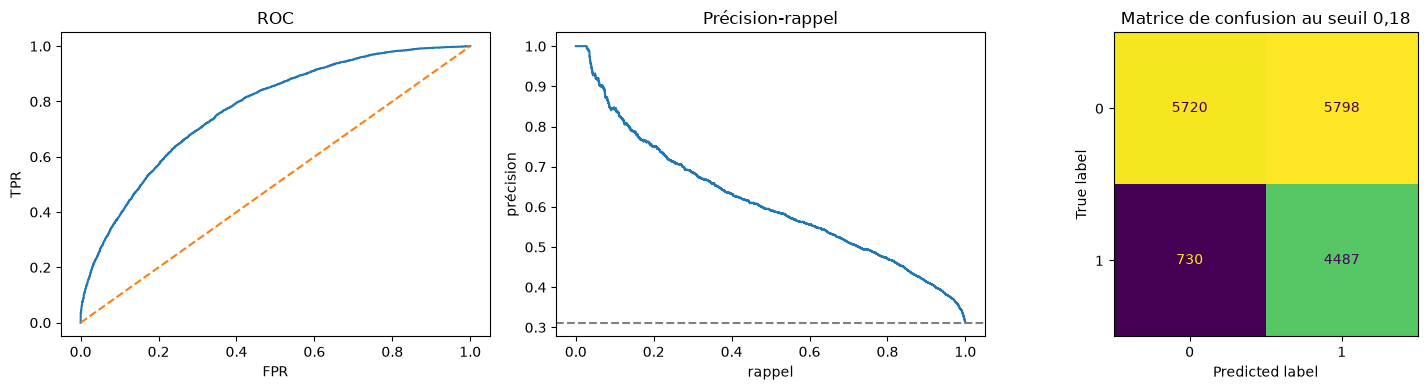

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

final = faire_pipeline(LogisticRegression(max_iter=1000))
X_app = pd.concat([X_tr, X_va]); y_app = pd.concat([y_tr, y_va])
final.fit(X_app, y_app)
p_te = final.predict_proba(X_te)[:, 1]
print("AUPRC test :", round(average_precision_score(y_te, p_te), 3),
      "| AUC :", round(roc_auc_score(y_te, p_te), 3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fpr, tpr, _ = roc_curve(y_te, p_te)
axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], "--")
axes[0].set_title("ROC"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
prec, rec, seuils = precision_recall_curve(y_te, p_te)
axes[1].plot(rec, prec); axes[1].axhline(y_te.mean(), ls="--", c="gray")
axes[1].set_title("Précision-rappel"); axes[1].set_xlabel("rappel"); axes[1].set_ylabel("précision")
ConfusionMatrixDisplay(confusion_matrix(y_te, p_te >= 0.18)).plot(ax=axes[2], colorbar=False)
axes[2].set_title("Matrice de confusion au seuil 0,18")
plt.tight_layout(); plt.show()

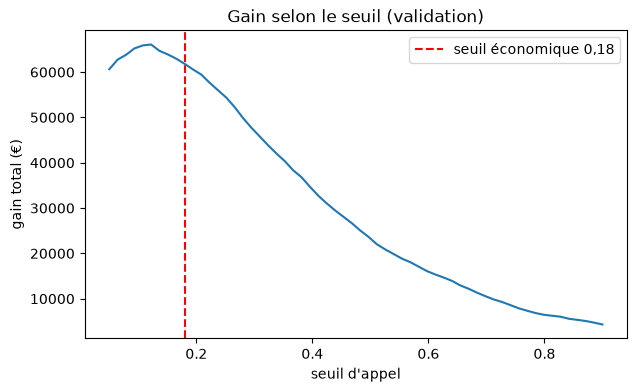

seuil optimal sur la validation : 0.12 | appels au seuil 0,18 : 40 % des dossiers


In [13]:
# Gain économique selon le seuil, calculé avec les VRAIES étiquettes :
# gain = y * (100/3) - 6 pour chaque dossier appelé.
# Tracée sur la VALIDATION (le test reste intact), seuil théorique = 0,18.
p_va = faire_pipeline(LogisticRegression(max_iter=1000)).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
grille = np.linspace(0.05, 0.9, 60)
gains = [((p_va >= s) * (y_va * 100 / 3 - 6)).sum() for s in grille]
plt.figure(figsize=(7, 4))
plt.plot(grille, gains)
plt.axvline(0.18, color="r", ls="--", label="seuil économique 0,18")
plt.xlabel("seuil d'appel"); plt.ylabel("gain total (€)"); plt.legend()
plt.title("Gain selon le seuil (validation)")
plt.show()
s_opt = grille[int(np.argmax(gains))]
print("seuil optimal sur la validation :", round(float(s_opt), 2),
      "| appels au seuil 0,18 :", round((p_va >= 0.18).mean() * 100), "% des dossiers")

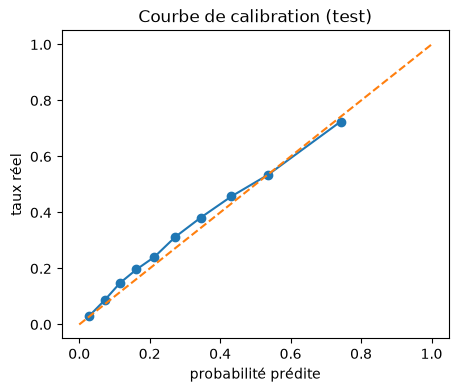

In [14]:
# Calibration : la probabilité prédite correspond-elle au taux réel ?
from sklearn.calibration import calibration_curve
vrais, predits = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
plt.figure(figsize=(5, 4))
plt.plot(predits, vrais, "o-"); plt.plot([0, 1], [0, 1], "--")
plt.xlabel("probabilité prédite"); plt.ylabel("taux réel")
plt.title("Courbe de calibration (test)")
plt.show()

## 8. Diagnostic de fitting

- La régression logistique a un écart train/validation faible : **pas de sur-apprentissage** (l'arbre illimité, lui, montre le contraste : 1,00 en train).
- Attention à la lecture : les **taux d'annulation diffèrent entre les jeux** (le test, plus récent, annule davantage) — l'AUPRC dépend du taux de base, donc train et test ne se comparent pas directement à valeur égale.
- Ni sous-apprentissage (AUPRC ≫ baseline) ni sur-apprentissage (train ≈ validation).

## 9. Interprétation pour un responsable commercial

Importance par permutation sur le test : quelles variables font monter le risque ?

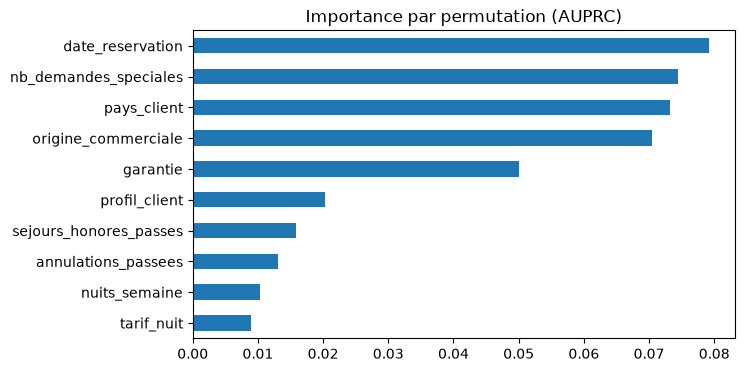

In [15]:
from sklearn.inspection import permutation_importance
sub = X_te.sample(5000, random_state=0)
r = permutation_importance(final, sub, y_te.loc[sub.index],
                           scoring="average_precision", n_repeats=5, random_state=0)
imp = pd.Series(r.importances_mean, index=sub.columns).sort_values()
imp.tail(10).plot.barh(figsize=(7, 4), title="Importance par permutation (AUPRC)")
plt.show()

## 10. Mise en production

`train.py` réentraîne ce pipeline et l'exporte dans `model.pkl` (+ `model_meta.json` :
variables, métriques, seuil, versions). `app.py` (Gradio) et `api.py` (FastAPI)
chargent le **pipeline entier** — préparation comprise — et le fichier
`features.py` doit accompagner le modèle (le pickle référence `build_features`).